Pedro Domitti de Carvalho - 21005320


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns

Questão 1:

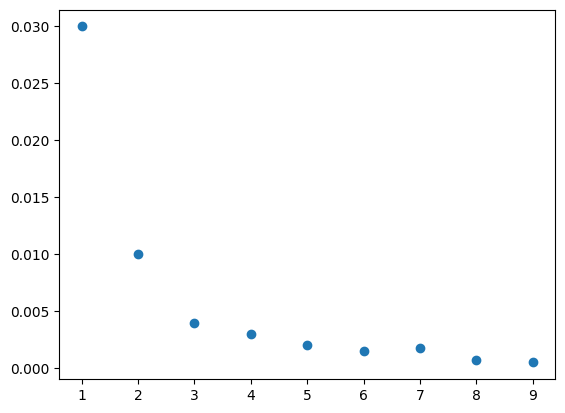

In [2]:
x = [1, 2, 3, 4, 5, 6, 7, 8, 9]
y = [0.03, 0.01, 0.004, 0.003, 0.002, 0.0015, 0.0018, 0.0007, 0.0005]

data = pd.DataFrame({'x': x, 'y': y})

plt.scatter(data['x'], data['y'])
plt.show()

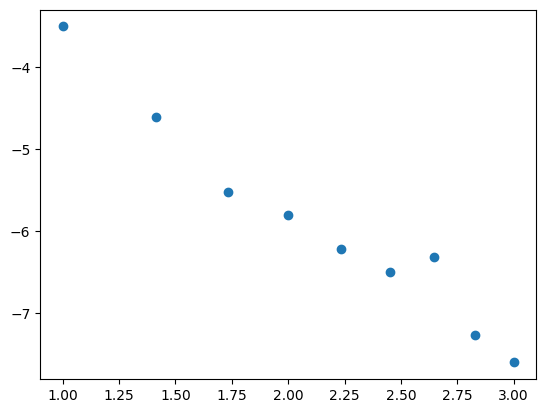

In [3]:
data['x*'] = np.sqrt(data['x'])
data['y*'] = np.log(data['y'])

plt.scatter(data['x*'], data['y*'])
plt.show()

In [4]:
slope, intercept, r_value, p_value, std_err = stats.linregress(data['x*'], data['y*'])

print('y = {}x + {}'.format(slope, intercept))

y = -1.8584508590392657x + -1.9405864772333192


In [5]:
a = np.exp(intercept)
m = slope

print('y = {} * e^({}x)'.format(a, m))

y = 0.14361969539187477 * e^(-1.8584508590392657x)


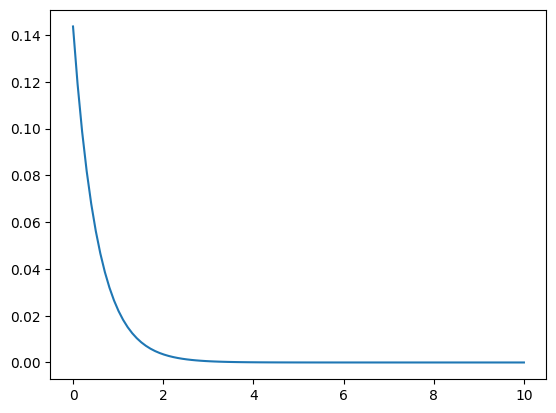

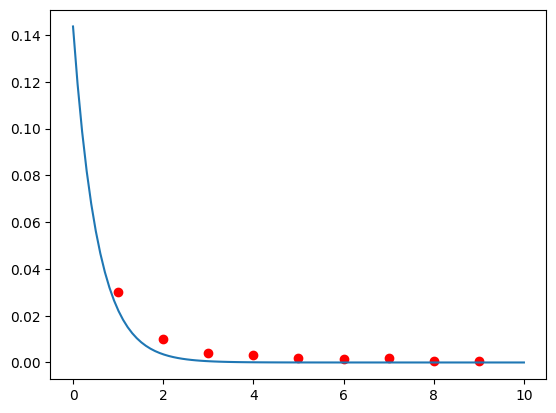

In [6]:
xp = np.linspace(0, 10, 100)

def g(x):
    return a * np.exp(m * x)

plt.plot(xp, g(xp))
plt.show()

plt.scatter(data['x'], data['y'], color='red')
plt.plot(xp, g(xp))
plt.show()

Questão 2:

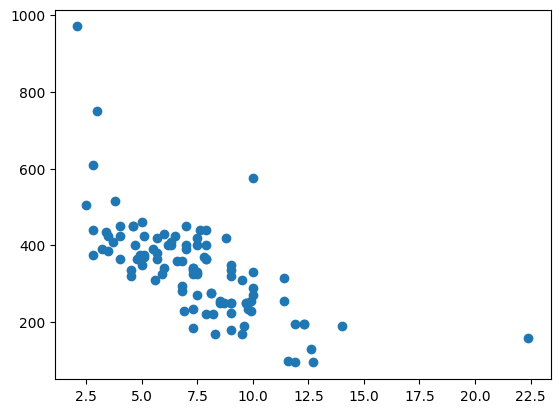

In [7]:
df = pd.read_excel('../data/cars.xlsx')

plt.scatter(df['Aceleração'], df['Autonomia'])
plt.show()

y = -28.27557807701226x + 547.915877466679
R = -0.677061995971595


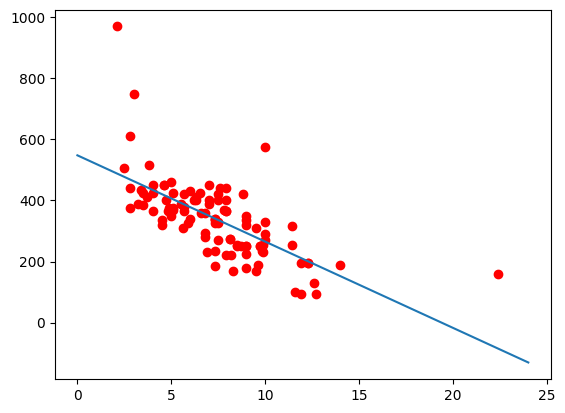

In [8]:
slope, intercept, r_value, p_value, std_err = stats.linregress(df['Aceleração'], df['Autonomia'])

print('y = {}x + {}'.format(slope, intercept))
print('R = {}'.format(r_value))

xp = np.linspace(0, 24, 100)

def g(x):
    return slope * x + intercept

plt.scatter(df['Aceleração'], df['Autonomia'], color='red')
plt.plot(xp, g(xp))
plt.show()

R com apenas Aceleração transformada: -0.7211189207005686
R com apenas Autonomia transformada: -0.71599604684941
R com ambas variáveis transformadas: -0.7409762853205457


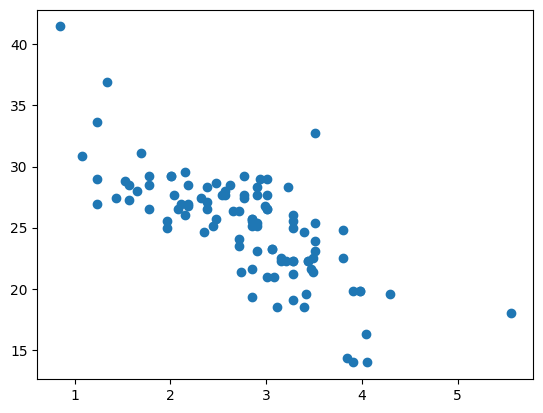

In [9]:
df['Aceleração*'], _ = stats.boxcox(df['Aceleração'])
df['Autonomia*'], _ = stats.boxcox(df['Autonomia'])

slope, intercept, r_value, p_value, std_err = stats.linregress(df['Aceleração*'], df['Autonomia'])
print('R com apenas Aceleração transformada: {}'.format(r_value))
slope, intercept, r_value, p_value, std_err = stats.linregress(df['Aceleração'], df['Autonomia*'])
print('R com apenas Autonomia transformada: {}'.format(r_value))
slope, intercept, r_value, p_value, std_err = stats.linregress(df['Aceleração*'], df['Autonomia*'])
print('R com ambas variáveis transformadas: {}'.format(r_value))

plt.scatter(df['Aceleração*'], df['Autonomia*'])
plt.show()

y = -4.030804248509965x + 36.3729568709921
R = -0.7409762853205457


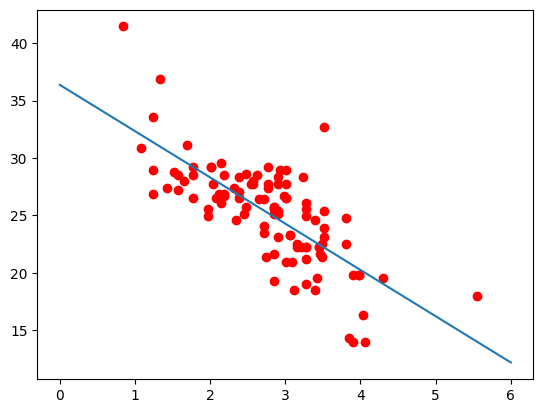

In [10]:
slope, intercept, r_value, p_value, std_err = stats.linregress(df['Aceleração*'], df['Autonomia*'])

print('y = {}x + {}'.format(slope, intercept))
print('R = {}'.format(r_value))

xp = np.linspace(0, 6, 100)

def g(x):
    return slope * x + intercept

plt.scatter(df['Aceleração*'], df['Autonomia*'], color='red')
plt.plot(xp, g(xp))
plt.show()

Questão 3:

In [11]:
# https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.normaltest.html
# Função do scipy baseada no teste de D’Agostino e Pearson que combina distorção e curtose para testar a normalidade.

def normalidade(data):
    _, p = stats.normaltest(data)

    print('P = {}'.format(p))

    # p < 0,05: Indica forte evidência contra a hipótese nula de normalidade, sugerindo que a variável pode não ter distribuição normal.
    if p < 0.05:
        return 'Não é normal'

    return 'É normal'

print('Aceleração: {}'.format(normalidade(df['Aceleração'])))
print('Autonomia: {}'.format(normalidade(df['Autonomia'])))

P = 8.26691696855162e-09
Aceleração: Não é normal
P = 3.4869830302250593e-10
Autonomia: Não é normal


In [12]:
print('Aceleração*: {}'.format(normalidade(df['Aceleração*'])))
print('Autonomia*: {}'.format(normalidade(df['Autonomia*'])))

P = 0.44195994298336516
Aceleração*: É normal
P = 0.03229312715652347
Autonomia*: Não é normal
